Bài 6 — Khi số đếm thô biến thành đồ họa gây hiểu sai: county

6.1. Trước hết, vẽ hai histogram với cùng bin edges nhưng trục y là số county

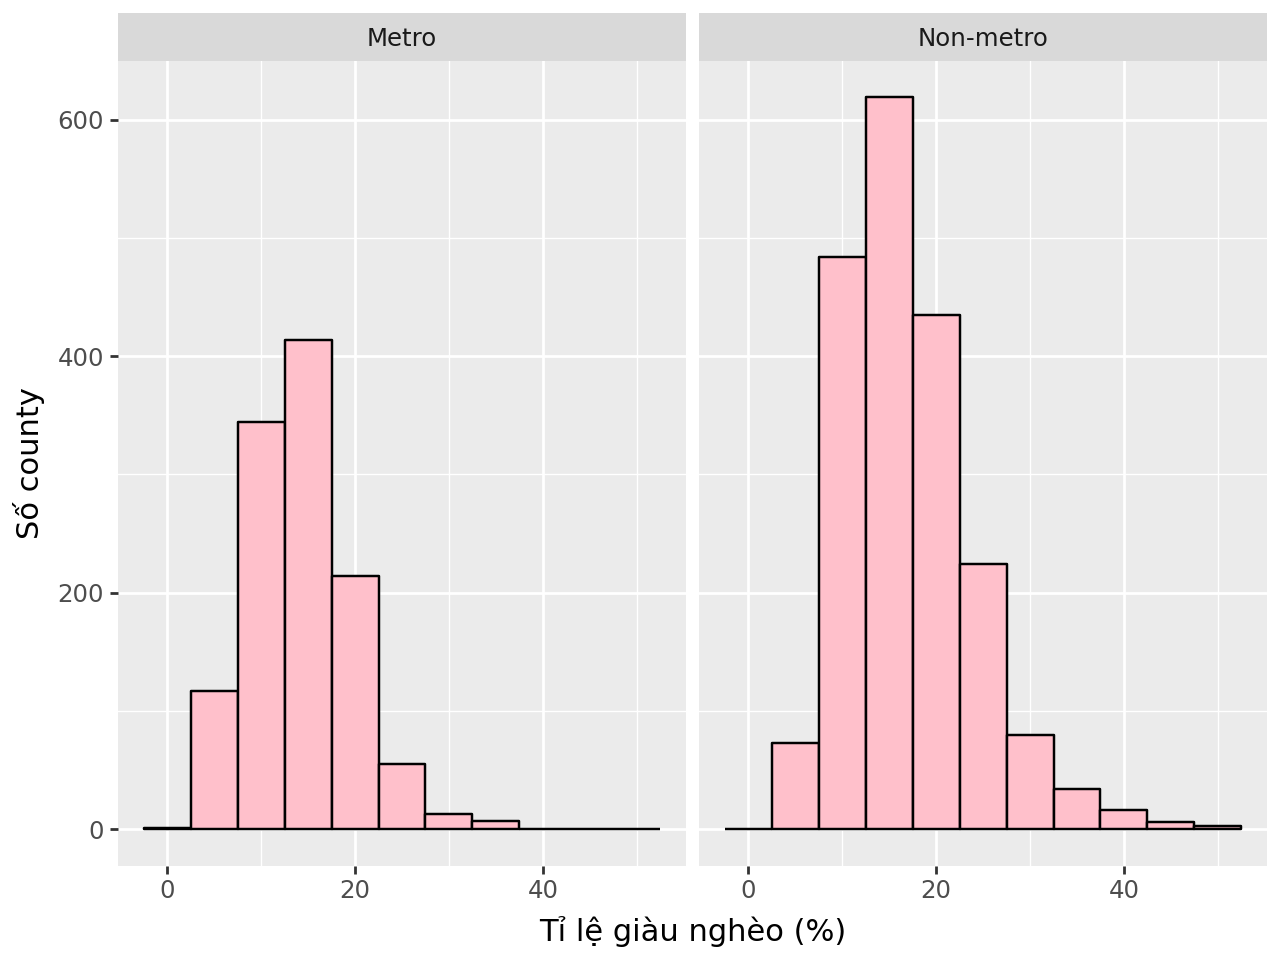

In [36]:
import pandas as pd
data = pd.read_csv("county.csv")
data = data.dropna(subset = ['metro'])
data['metro'] = data['metro'].replace({
    'no': 'Non-metro',
    'yes': 'Metro'
})
from plotnine import*
(
    ggplot(
        data,
        aes(x = "poverty")) 
        + geom_histogram(
            binwidth = 5,
            color = 'black',
            fill = 'pink')
        + facet_wrap('metro')
        +labs(
            x = 'Tỉ lệ giàu nghèo (%)',
            y = 'Số county'
        )
)

6.2. Ghi lại kích thước hai nhóm. Từ đó giải thích vì sao chỉ nhìn chiều cao số đếm có thể
đánh đồng “nhóm đông hơn” với “phân phối tập trung hơn”.


In [23]:
print(data['metro'].value_counts())

metro
Non-metro    1974
Metro        1165
Name: count, dtype: int64


6.3. Vẽ lại bằng tỉ lệ hoặc density sao cho diện tích mỗi histogram tương ứng với 100% của
chính nhóm đó.

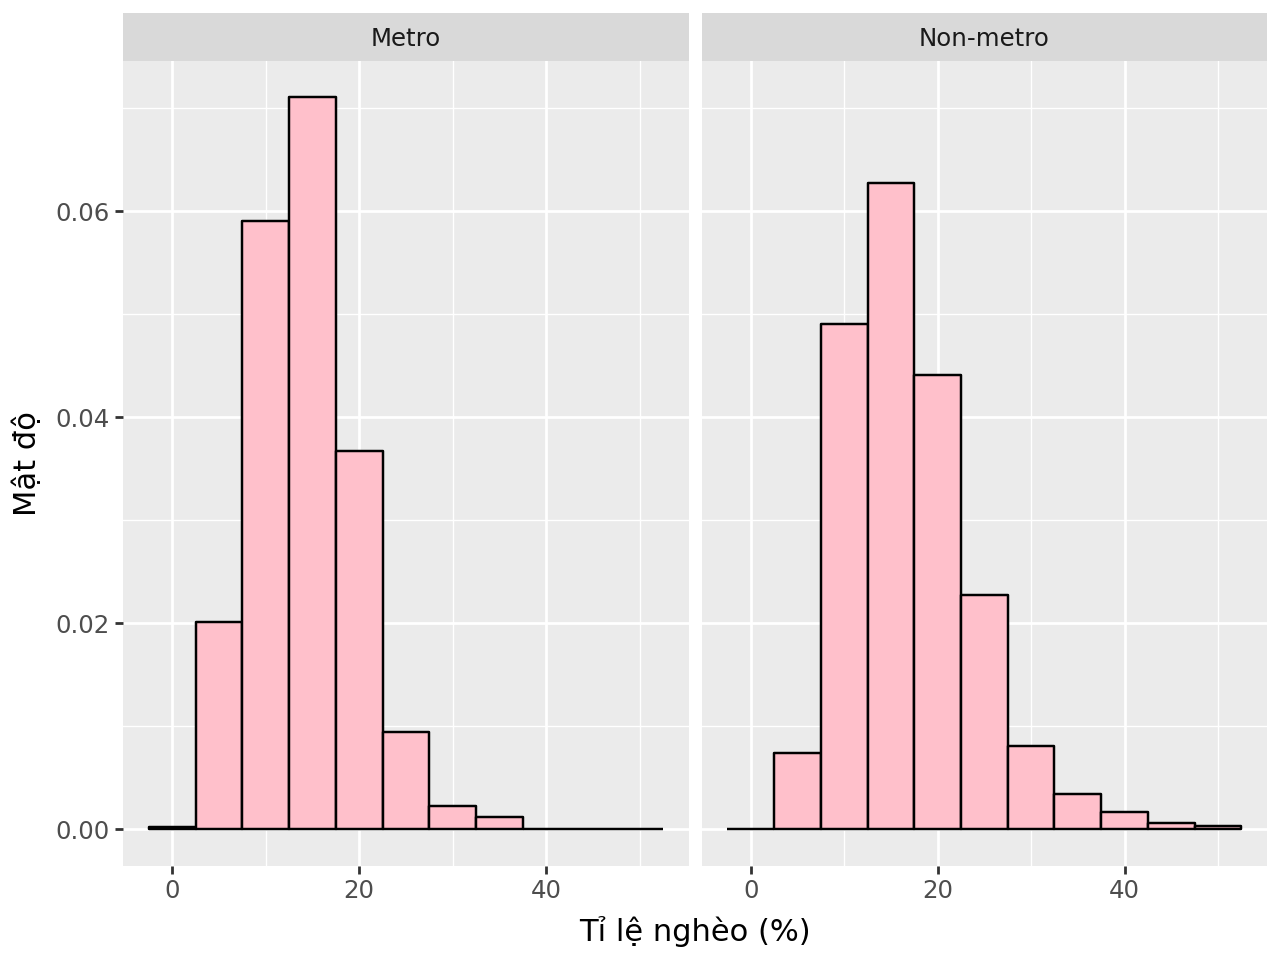

In [33]:
(
    ggplot(
        data,
        aes(x = 'poverty')
    )
    + geom_histogram(
        aes(y = '..density..'),
        binwidth = 5,
        color = 'black',
        fill = 'pink'
    )
    + facet_wrap('metro')
    +labs(
        x = 'Tỉ lệ nghèo (%)',
        y = 'Mật độ'
    )
)

Bài 7 — Heaping ở chữ số cuối: run10


7.1. Bỏ tuổi thiếu. Tạo biến last_digit = age % 10.


In [53]:
import pandas as pd
from plotnine import *
run10 = pd.read_csv('run10.csv')
moi = run10.dropna(subset = ['age']).copy()
moi['last_digit'] = moi['age'] % 10

7.2. Vẽ biểu đồ tỉ lệ cho 10 chữ số cuối 0–9.

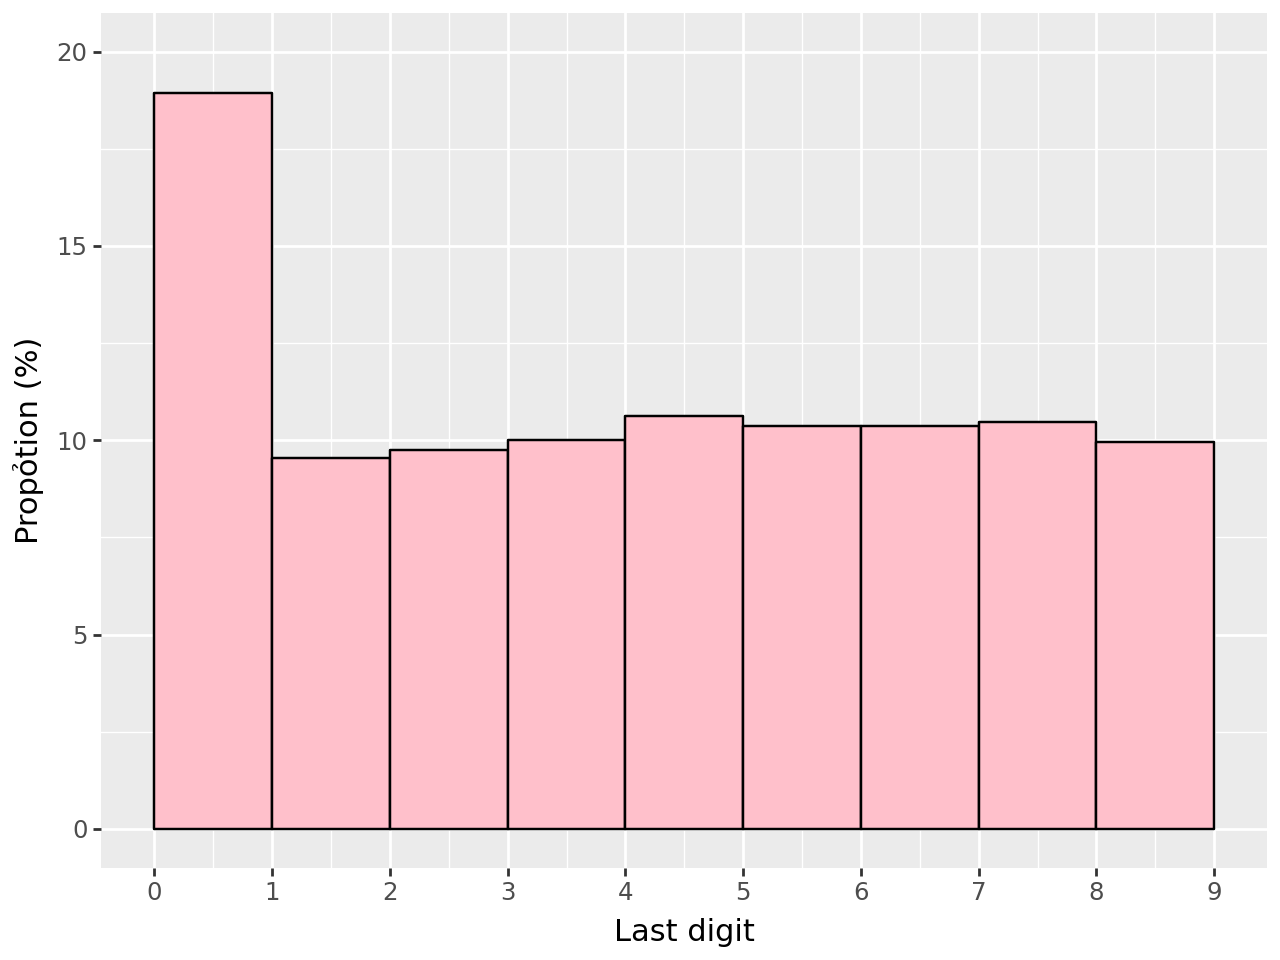

In [71]:
(
    ggplot(
        moi,
        aes(x = 'last_digit'))
        + geom_histogram(
            aes(y = '..density..'),
            binwidth = 1,
            boundary = 0,
            color = 'black',
            fill = 'pink'
        )
        + scale_x_continuous(breaks = range(10))
        +scale_y_continuous(
            limits = (0, 0.20),
            breaks = [0, 0.05, 0.10, 0.15, 0.20],
            labels = [0, '5', '10', '15', '20']
        )
        + labs(
            x = 'Last digit',
            y = 'Propỏtion (%)'
        )
)

7.4. Tính tổng tỉ lệ tuổi kết thúc bằng 0 hoặc 5. Có dấu hiệu “heaping” tại các số tròn không?

In [82]:
moi['last_digit'].value_counts(normalize = True)
tong_ti_le_0_or_5 = moi['last_digit'].value_counts(normalize = True)[[0, 5]].sum()
sum = round(tong_ti_le_0_or_5 * 100, 2)
print(sum)

20.4


7.5. Điều kiện hóa theo gender hoặc theo div và kiểm tra xem hình dạng có còn tương tự
không.

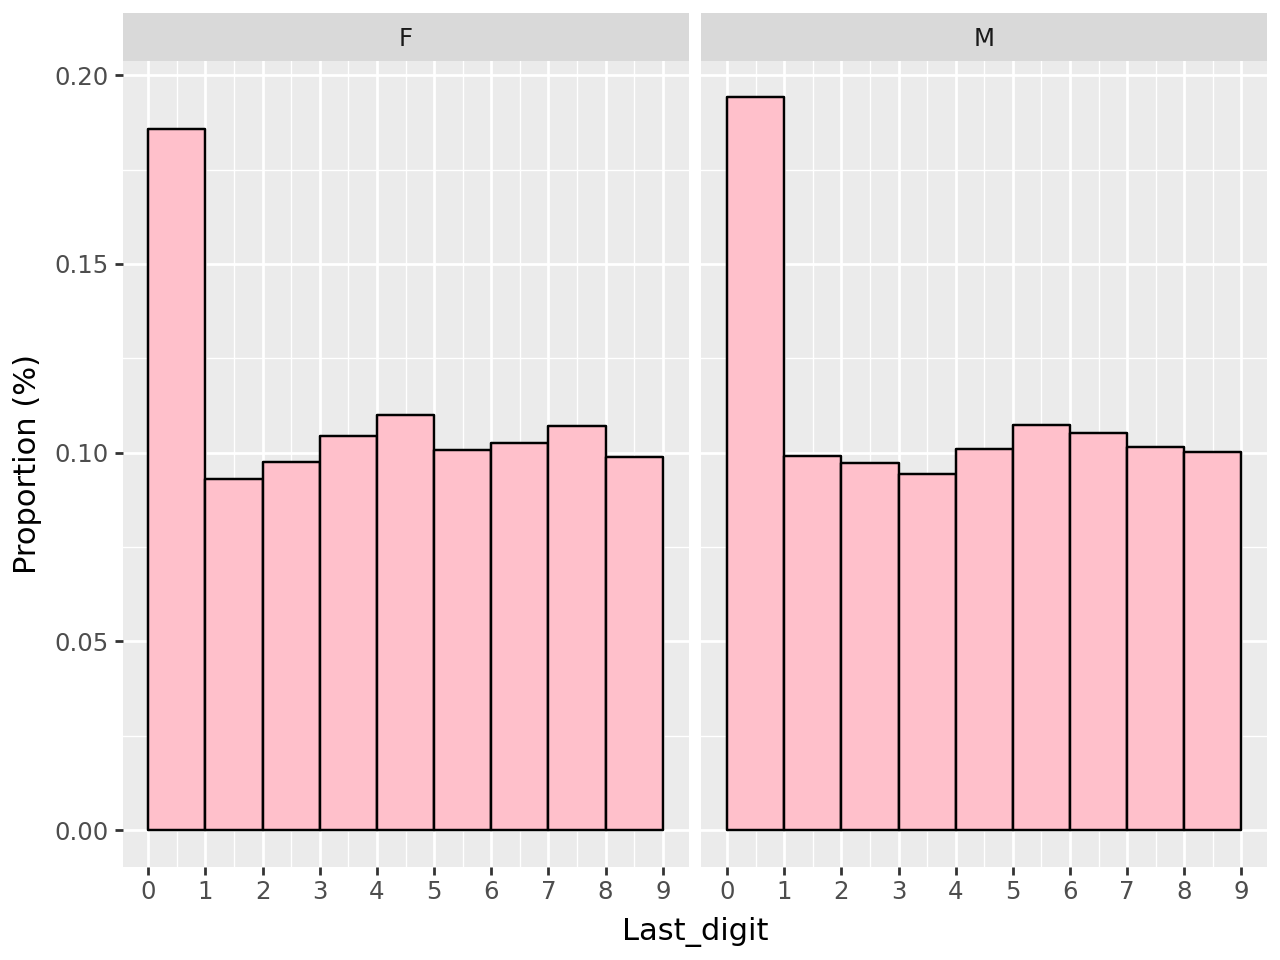

In [83]:
#gender
(
    ggplot(moi, aes(x='last_digit'))
    + geom_histogram(
        aes(y='..density..'),
        binwidth=1,
        boundary=0,
        color='black',
        fill='pink'
    )
    + facet_wrap('~gender')
    + scale_x_continuous(breaks=range(10))
    + labs(
        x='Last_digit',
        y='Proportion (%)'
    )
)

Bài 8 — Một đỉnh bất thường có phải là bằng chứng thao túng? exam_grades


8.1. Vẽ histogram course_grade với bin width 5 điểm.

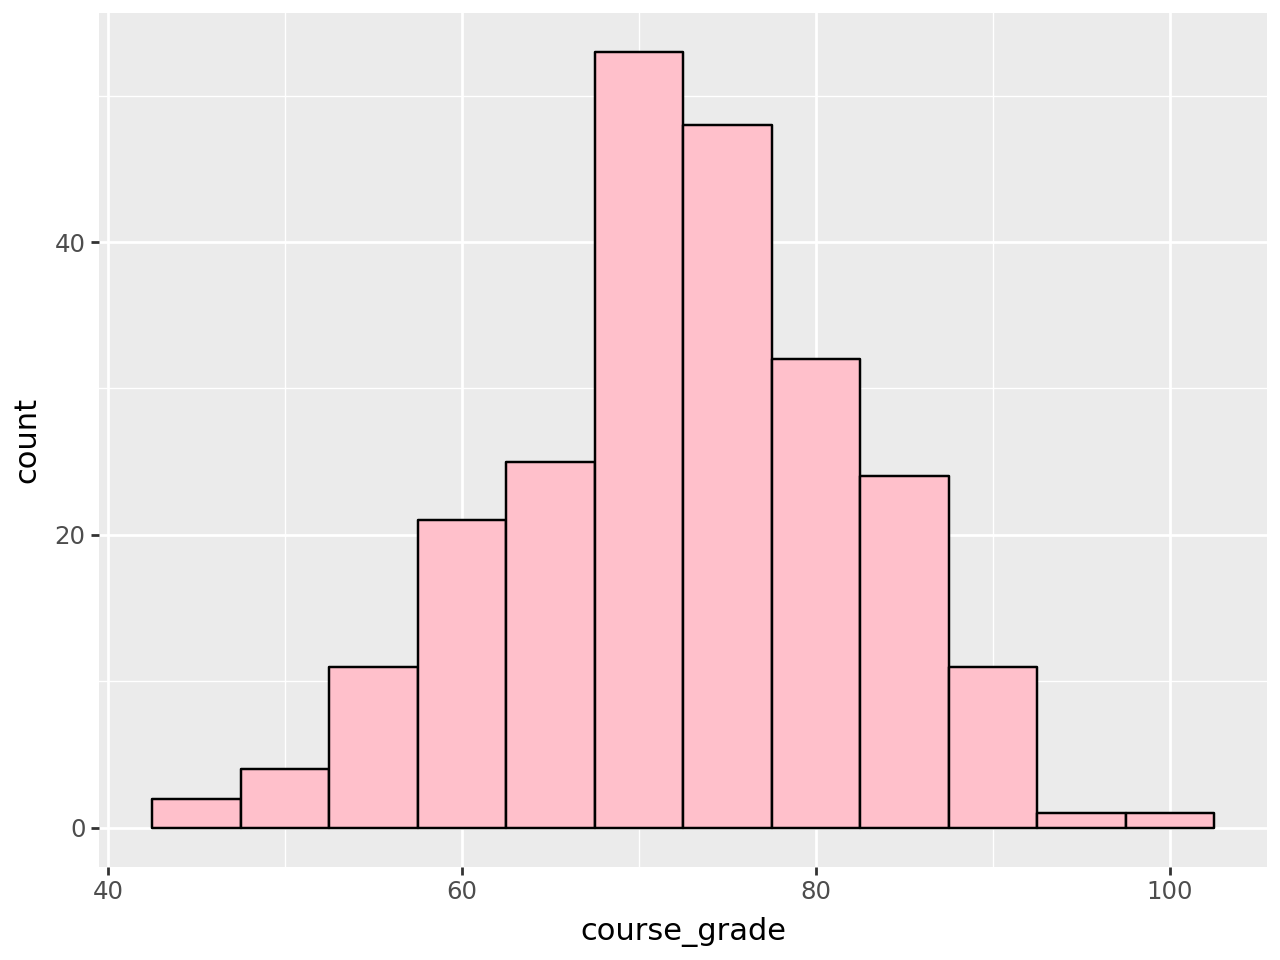

In [92]:
import pandas as pd
from plotnine import *
e_g = pd.read_csv('exam_grades.csv')
(
    ggplot(
        e_g,
        aes(x = 'course_grade'))
        + geom_histogram(
            binwidth = 5,
            color = 'black',
            fill = 'pink'
        )
)

8.2. Vẽ lại với bin width 1 điểm. Ghi rõ các bin edges.


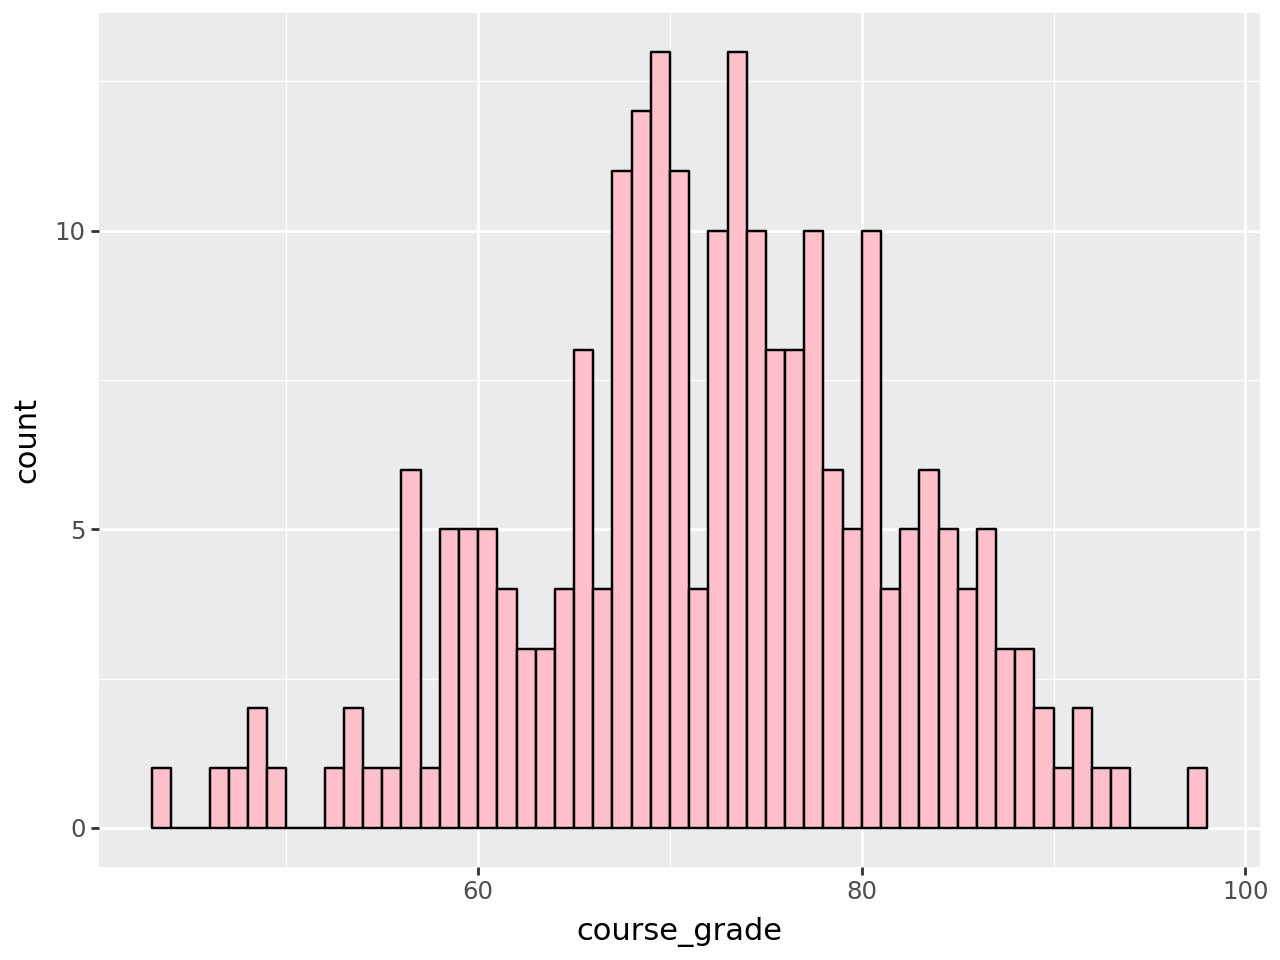

In [94]:
(
    ggplot(e_g, aes(x='course_grade'))
    + geom_histogram(
        binwidth=1,
        boundary=0,
        color='black',
        fill = 'pink'
    )
)

8.4. Điều kiện hóa theo semester: cùng một cấu trúc có lặp lại qua các học kỳ hay chủ yếu
đến từ một học kỳ?

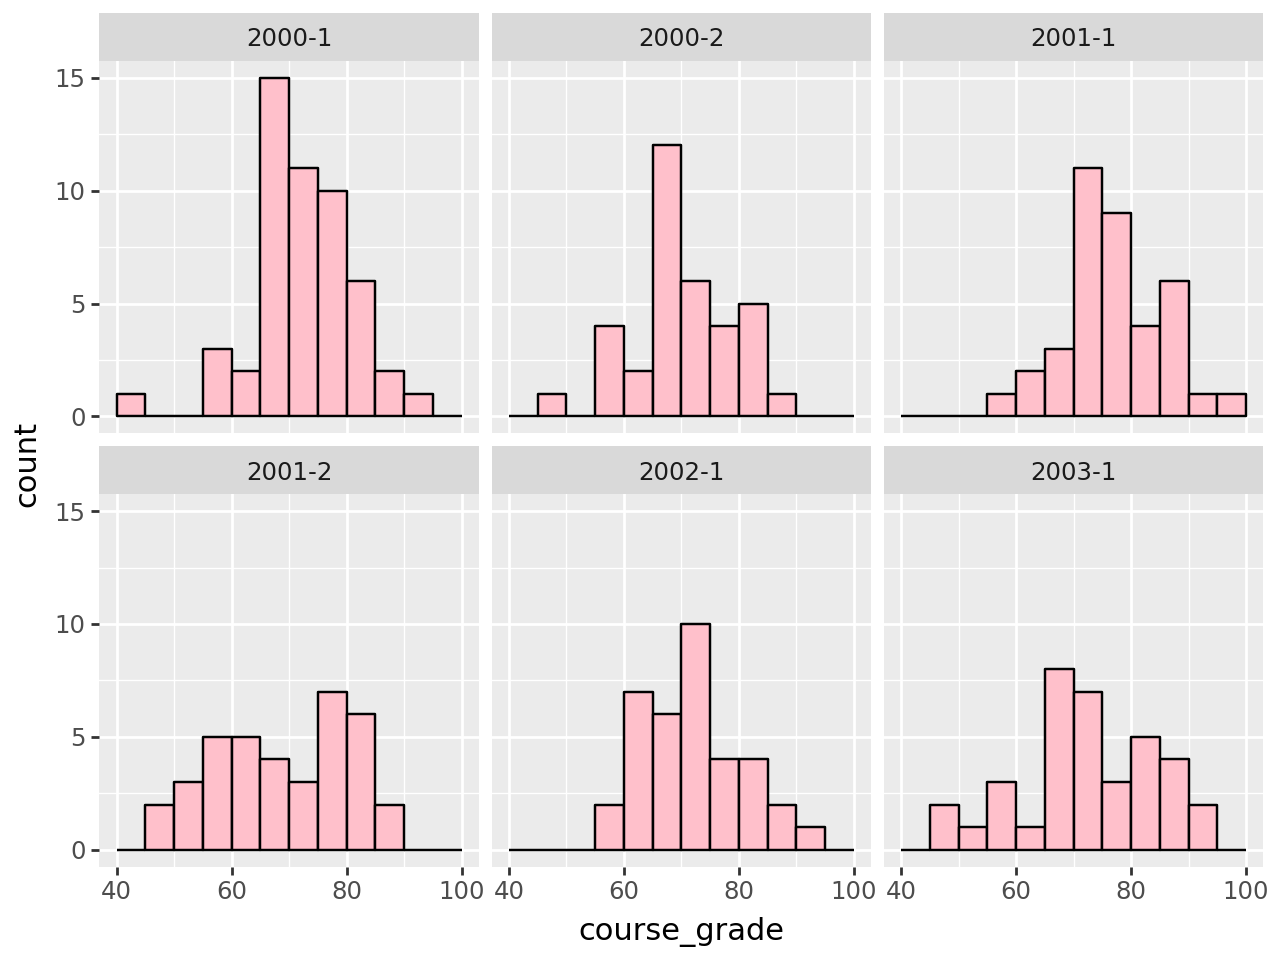

In [97]:
(
    ggplot(e_g, aes(x='course_grade'))
    + geom_histogram(
        binwidth=5,
        boundary=0,
        color='black',
        fill = 'pink'
    )
    + facet_wrap('semester')
)

8.5. Kiểm tra xem các điểm exam1, exam2, exam3 có hiện tượng tương tự không.

c:\Users\Windows\anaconda3\Lib\site-packages\plotnine\layer.py:293: PlotnineWarning: stat_bin : Removed 1 rows containing non-finite values.


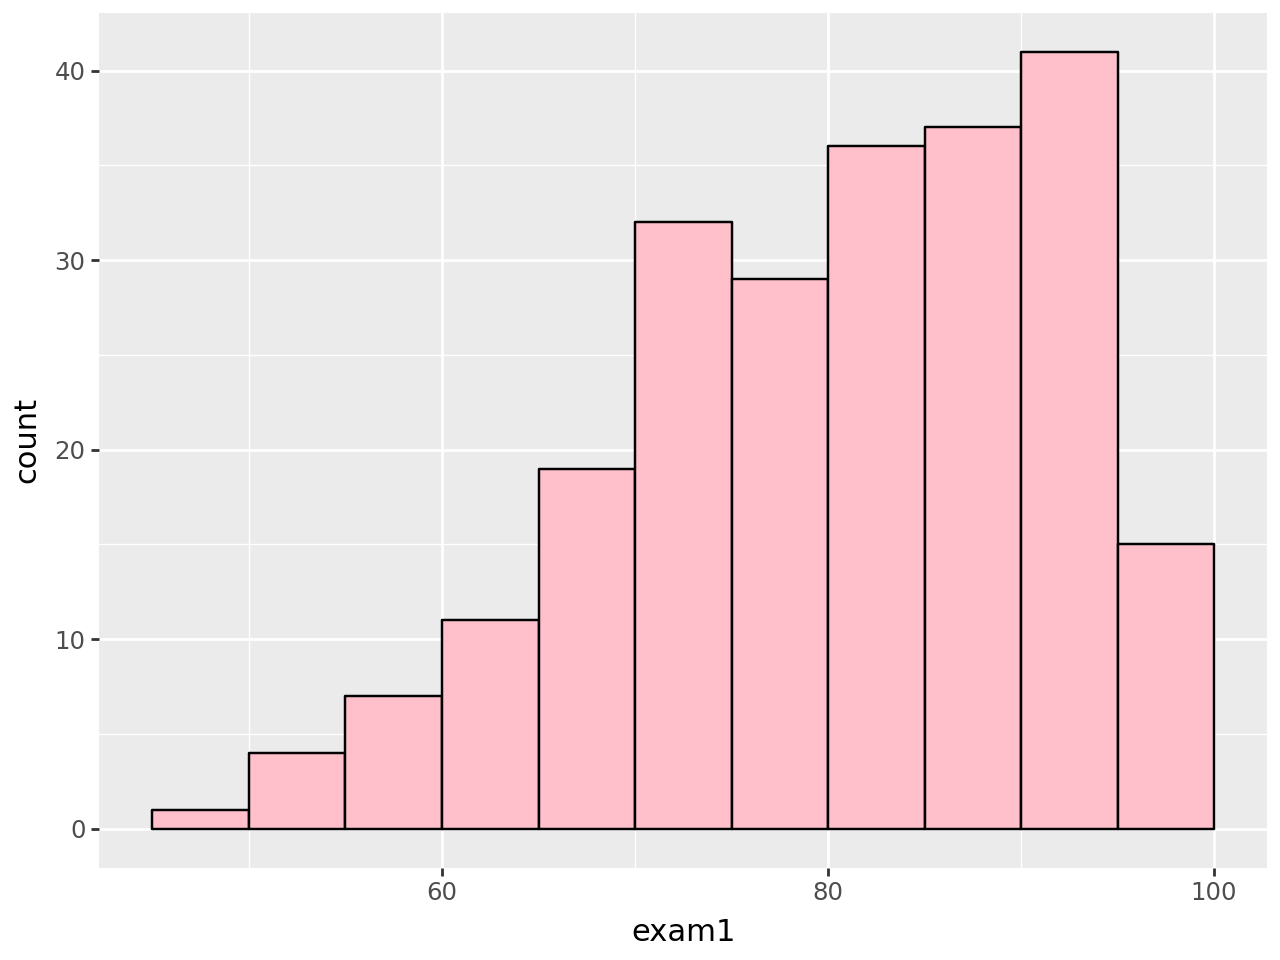

In [102]:
(
    ggplot(e_g, aes(x='exam1'))
    + geom_histogram(binwidth=5, boundary=0, color='black', fill = 'pink')
)

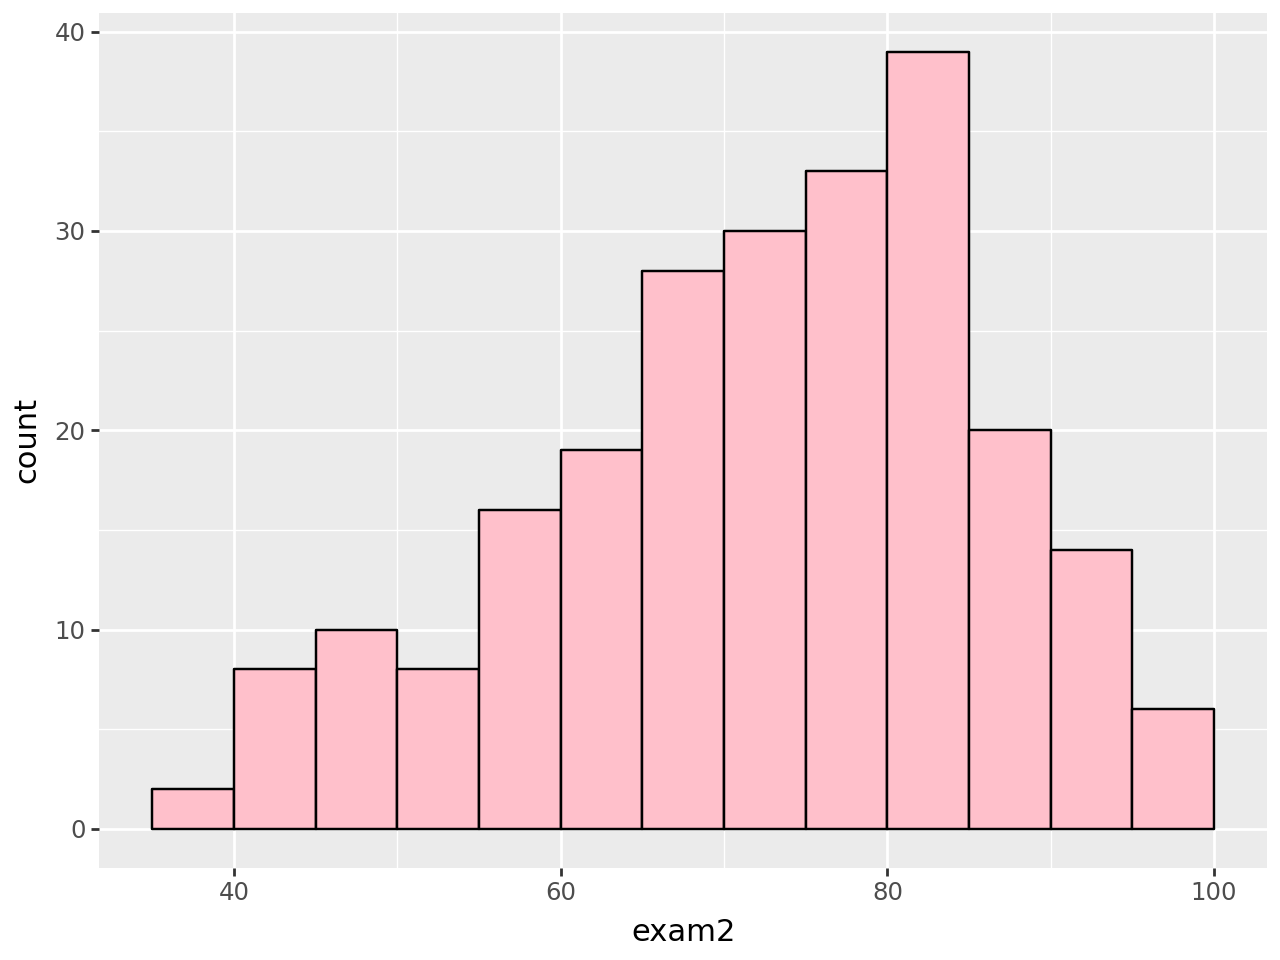

In [103]:
(
    ggplot(e_g, aes(x='exam2'))
    + geom_histogram(binwidth=5, boundary=0, color='black', fill = 'pink')
)

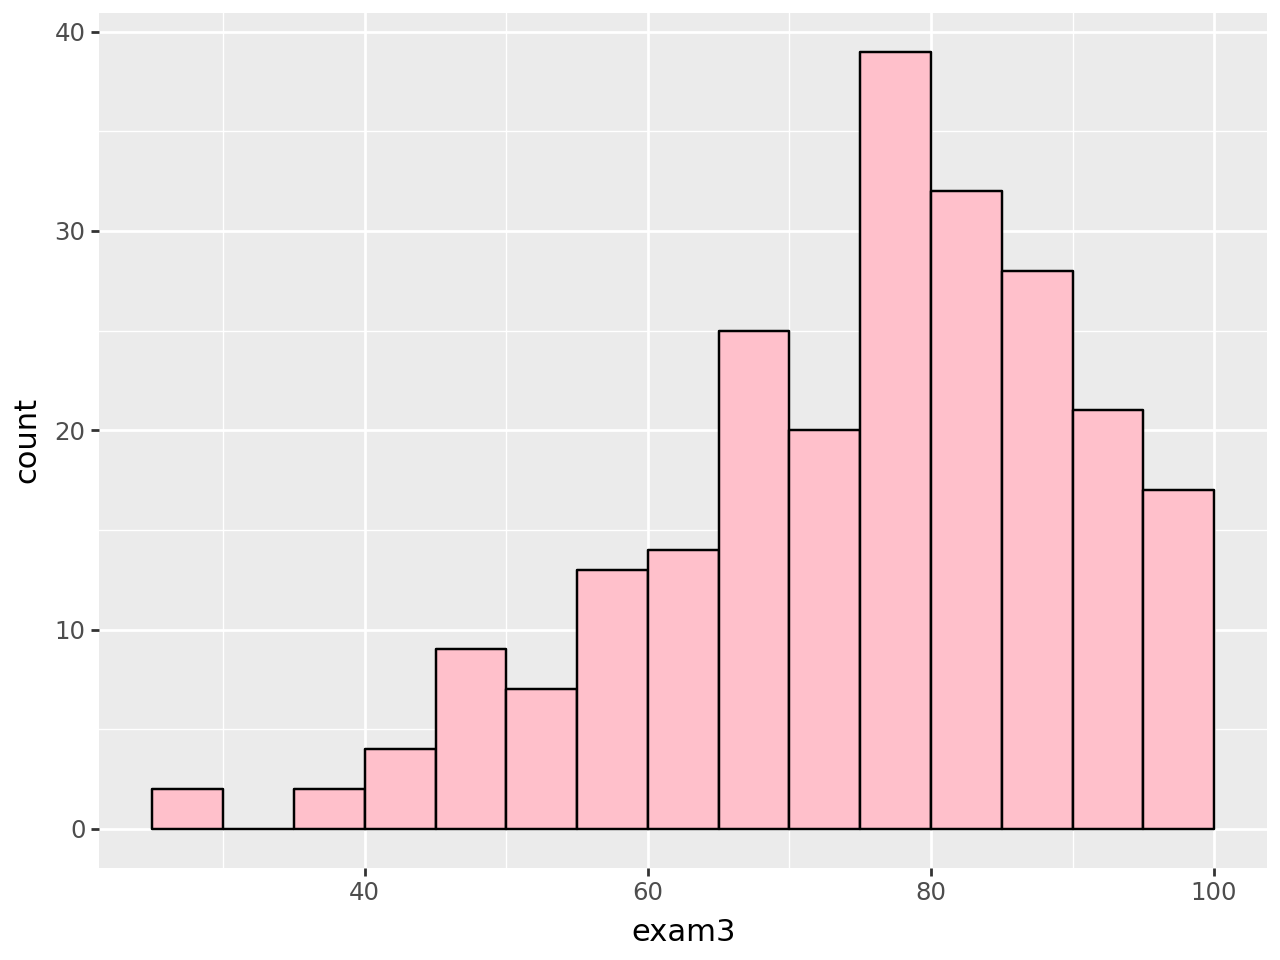

In [104]:
(
    ggplot(e_g, aes(x='exam3'))
    + geom_histogram(binwidth=5, boundary=0, color='black', fill = 'pink')
)

Bài 9 — Nhìn gộp hay nhìn trong nhóm? loans_full_schema

9.1. Tính và biểu diễn phân phối interest_rate theo homeownership ở mức biên

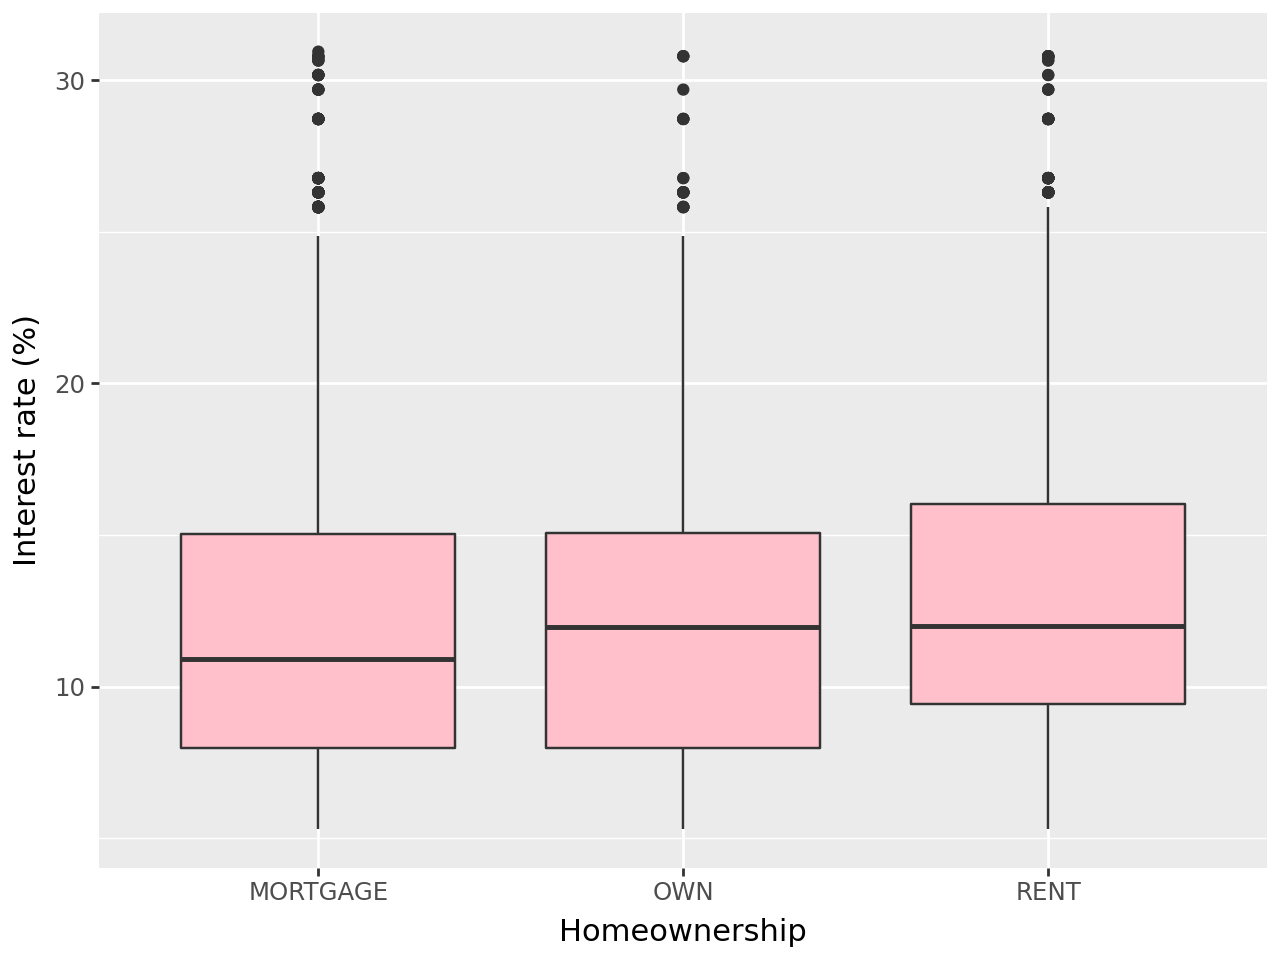

In [107]:
import pandas as pd
from plotnine import *
loans = pd.read_csv('loans_full_schema.csv')
(
    ggplot(loans, aes(x='homeownership', y='interest_rate'))
    + geom_boxplot(fill = 'pink')
    + labs(
        x='Homeownership',
        y='Interest rate (%)'
    )
)

9.2. Sau đó điều kiện hóa theo grade: trong từng grade, so sánh RENT với MORTGAGE/OWN bằng
cùng một loại tóm tắt.


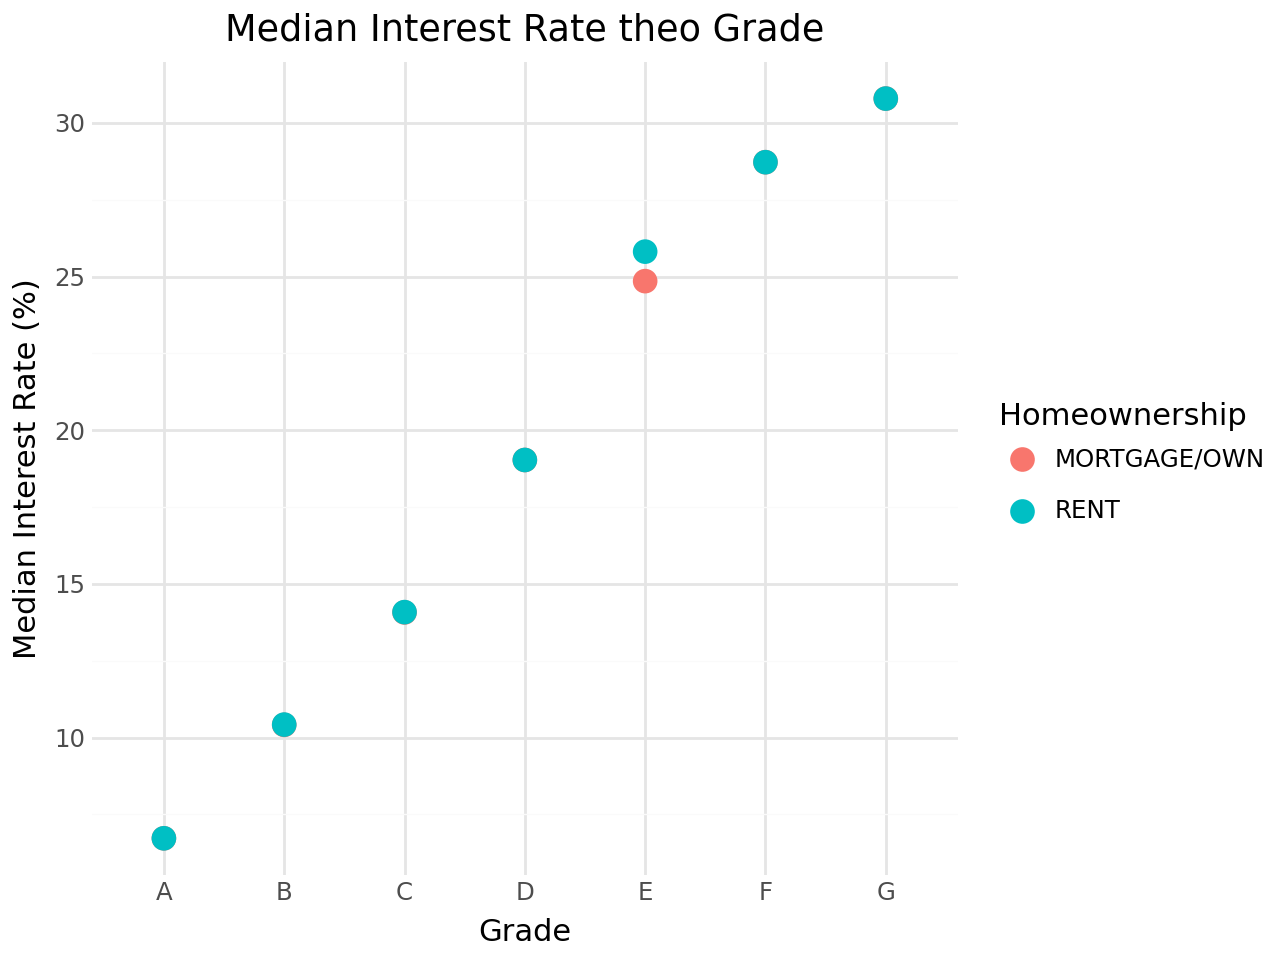

In [121]:
(
    ggplot(
        summary_grade,
        aes(
            x="grade",
            y="interest_rate",
            color="home_group"
        )
    )
    + geom_point(size=4)
    + labs(
        title="Median Interest Rate theo Grade",
        x="Grade",
        y="Median Interest Rate (%)",
        color="Homeownership"
    )
    + theme_minimal()
)

9.4. Giải thích bằng trọng số nhóm: phân bố grade có giống nhau giữa các nhóm
homeownership không?


In [122]:
grade_home = (
    pd.crosstab(
        df2["home_group"],
        df2["grade"],
        normalize="index"
    ) * 100
)

grade_home.round(2)

grade,A,B,C,D,E,F,G
home_group,,,,,,,
MORTGAGE/OWN,26.57,31.15,25.55,12.99,3.03,0.60,0.11
RENT,21.44,29.13,28.10,16.80,3.86,0.54,0.13


Bài 10 — Histogram của “các ca xảy ra” không phải histogram của “nguy cơ”:
ncbirths

10.1. Lọc chỉ các ca premie và vẽ histogram mage với các nhóm tuổi 5 năm. Đây là phân phối
của cái gì?

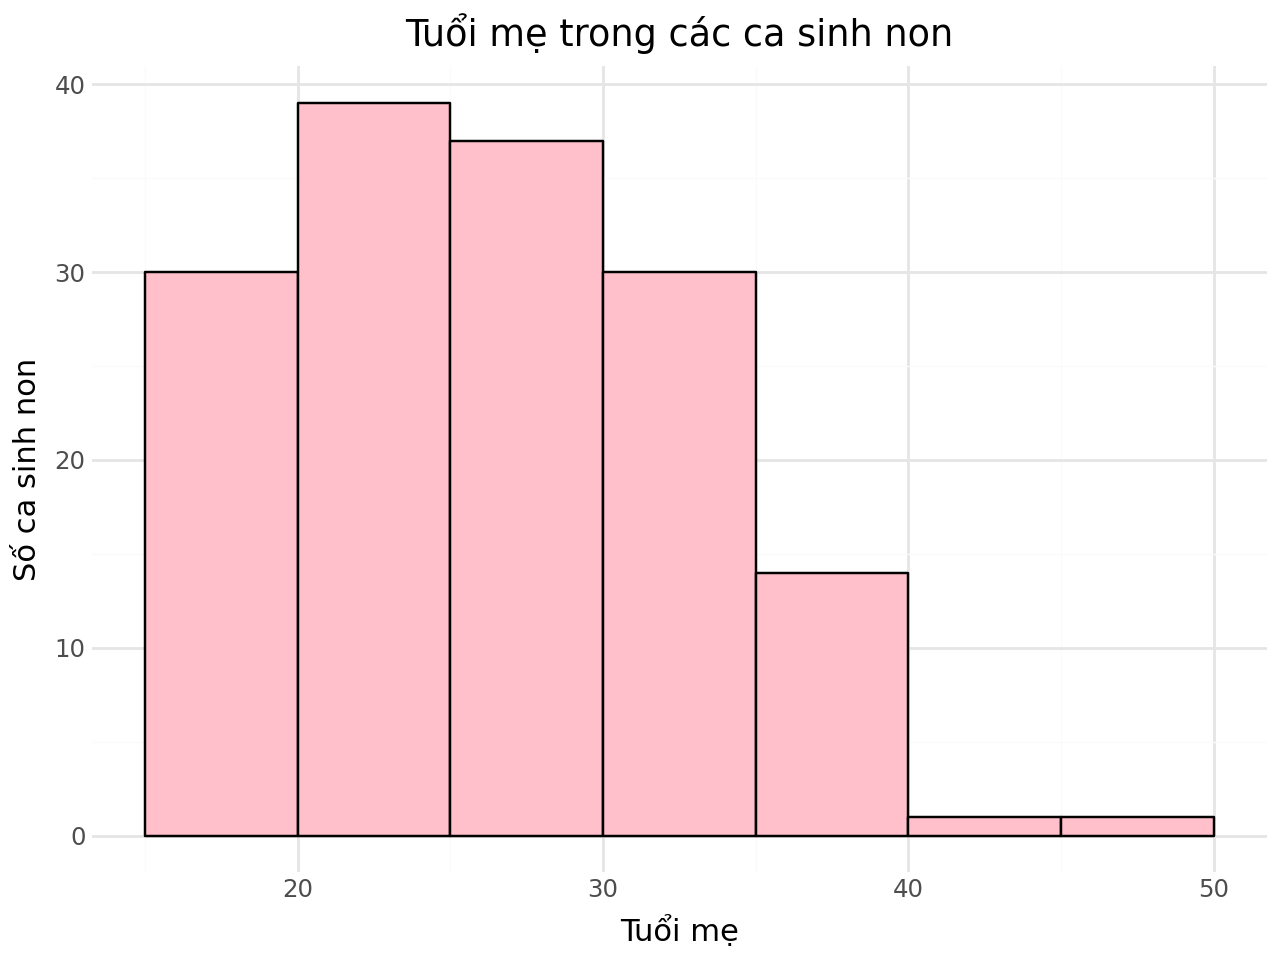

In [123]:
import pandas as pd
ncbirths = pd.read_csv("ncbirths.csv")
from plotnine import *

premie_births = ncbirths[ncbirths["premie"] == "premie"]

(
    ggplot(premie_births, aes(x="mage"))
    + geom_histogram(
        binwidth=5,
        boundary=0,
        color="black",
        fill="pink"
    )
    + labs(
        title="Tuổi mẹ trong các ca sinh non",
        x="Tuổi mẹ",
        y="Số ca sinh non"
    )
    + theme_minimal()
)

10.2. Với cùng các nhóm tuổi, đếm tất cả ca sinh trong từng nhóm tuổi mẹ.


10.3. Tính
prematurity rate trong nhóm tuổi =
(số ca premie trong nhóm tuổi)/
(tổng số ca sinh trong nhóm tuổi).

In [131]:
age_summary = (
    ncbirths
    .groupby("age_group", observed=True)
    .agg(
        total_births=("premie", "size"),
        premie_cases=("premie", lambda x: (x == "premie").sum())
    )
    .reset_index()
)

age_summary["premie_rate"] = (
    age_summary["premie_cases"] /
    age_summary["total_births"]
)

age_summary["premie_rate_percent"] = (
    age_summary["premie_rate"] * 100
)

age_summary = age_summary.round(2)

age_summary

,age_group,total_births,premie_cases,premie_rate,premie_rate_percent
0,"[10, 15)",2,0,0.00,0.00
1,"[15, 20)",108,21,0.19,19.44
2,"[20, 25)",281,42,0.15,14.95
3,"[25, 30)",257,35,0.14,13.62
4,"[30, 35)",219,31,0.14,14.16
5,"[35, 40)",111,18,0.16,16.22
6,"[40, 45)",19,4,0.21,21.05
7,"[45, 50)",2,1,0.50,50.00
8,"[50, 55)",1,0,0.00,0.00


10.4. Vẽ hai đồ họa cạnh nhau về mặt ý tưởng (không cần subplot):
• số ca premie theo nhóm tuổi;
• tỉ lệ premie theo nhóm tuổi.

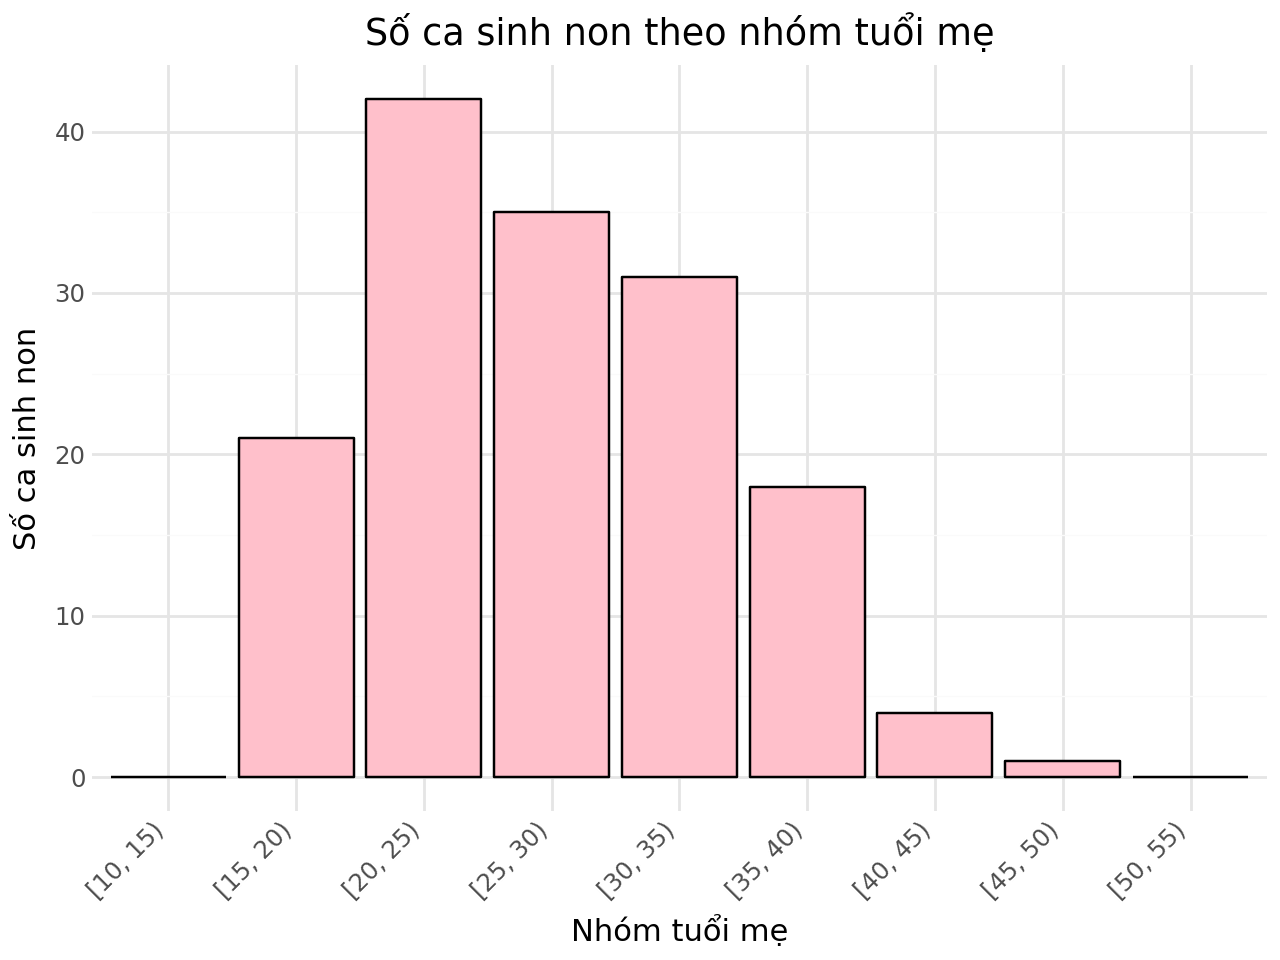

In [ ]:
# số ca sinh non theo nhóm tuổi
(
    ggplot(age_summary, aes(x="age_group", y="premie_cases"))
    + geom_col(fill="pink", color="black")
    + labs(
        title="Số ca sinh non theo nhóm tuổi mẹ",
        x="Nhóm tuổi mẹ",
        y="Số ca sinh non"
    )
    + theme_minimal()
    + theme(axis_text_x=element_text(rotation=45, ha="right"))
)

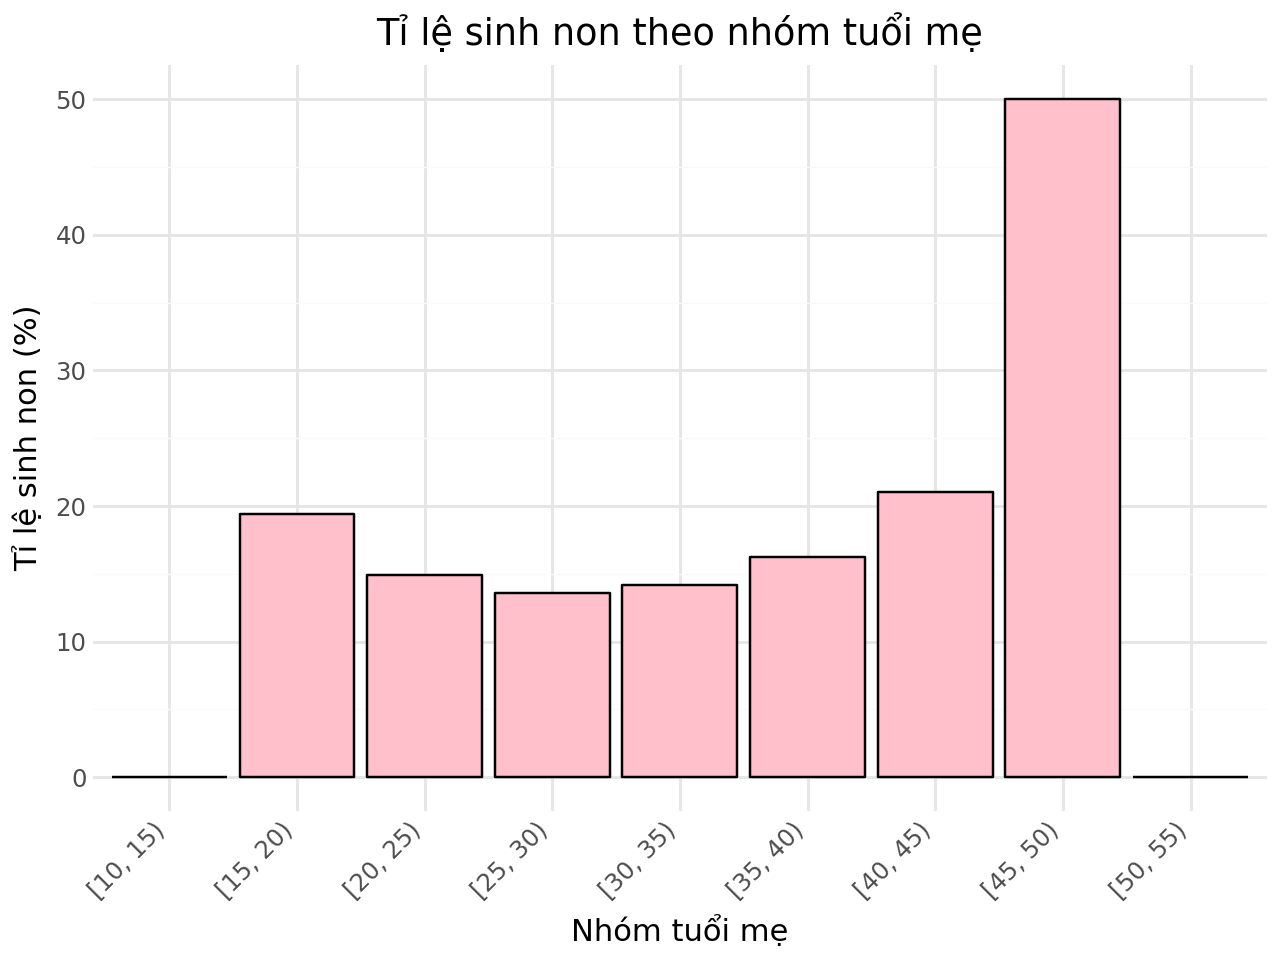

In [126]:
# tỉ lệ sinh non theo nhóm tuổi
(
    ggplot(age_summary, aes(x="age_group", y="premie_rate_percent"))
    + geom_col(fill="pink", color="black")
    + labs(
        title="Tỉ lệ sinh non theo nhóm tuổi mẹ",
        x="Nhóm tuổi mẹ",
        y="Tỉ lệ sinh non (%)"
    )
    + theme_minimal()
    + theme(axis_text_x=element_text(rotation=45, ha="right"))
)

10.5. Nhóm có nhiều ca sinh non nhất có nhất thiết là nhóm có tỉ lệ sinh non cao nhất
không? Báo cáo kết quả thật của dữ liệu.

In [132]:
age_summary.loc[
    age_summary["premie_cases"].idxmax(),
    ["age_group", "premie_cases"]
]

age_group       [20, 25)
premie_cases          42
Name: 2, dtype: object

In [133]:
age_summary.loc[
    age_summary["premie_rate"].idxmax(),
    ["age_group", "premie_rate_percent"]
]

age_group              [45, 50)
premie_rate_percent        50.0
Name: 7, dtype: object

10.7. Điều kiện hóa thêm theo habit (smoker/nonsmoker) hoặc mature và mô tả điều gì thay
đổi. Không suy diễn nhân quả.


In [127]:
habit_summary = (
    ncbirths
    .groupby(["habit", "age_group"], observed=True)
    .agg(
        total_births=("premie", "size"),
        premie_cases=("premie", lambda x: (x == "premie").sum())
    )
    .reset_index()
)

habit_summary["premie_rate_percent"] = (
    habit_summary["premie_cases"] /
    habit_summary["total_births"] * 100
)

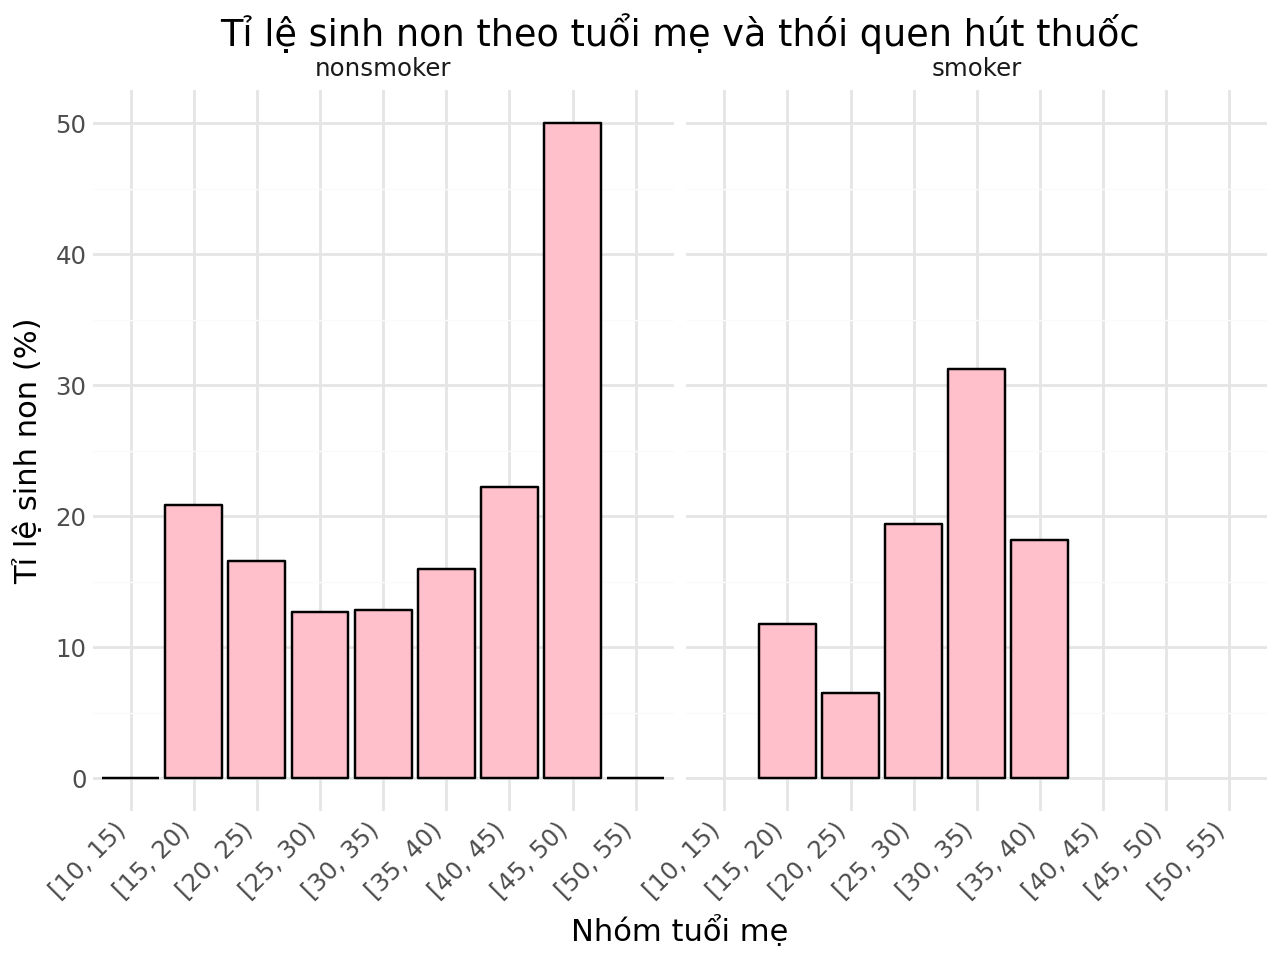

In [128]:
(
    ggplot(
        habit_summary,
        aes(x="age_group", y="premie_rate_percent")
    )
    + geom_col(fill="pink", color="black")
    + facet_wrap("~habit")
    + labs(
        title="Tỉ lệ sinh non theo tuổi mẹ và thói quen hút thuốc",
        x="Nhóm tuổi mẹ",
        y="Tỉ lệ sinh non (%)"
    )
    + theme_minimal()
    + theme(axis_text_x=element_text(rotation=45, ha="right"))
)